# GLANCE: Mouse trachea single-cell proteomics

This tutorial demonstrates **batch integration** and **protein-level abundance score inference** with GLANCE, followed by UMAP visualization and cell–cell correlation analysis.

The mouse trachea single-cell proteomics data and corresponding cell annotations are available from the [Slavov Lab processed-data page](https://scp.slavovlab.net/Leduc_et_al_2025#proc_data).

**Reference:** Leduc A, et al. *Principles of protein abundance regulation across single cells in a mammalian tissue*. *bioRxiv* (2025). [doi:10.1101/2025.09.17.676955](https://doi.org/10.1101/2025.09.17.676955).

## 1. Setup

The example uses `glancevae`, `scanpy`, `anndata`, `pandas`, `scikit-learn`, and `matplotlib`. PyTorch runs on a CUDA GPU when available and otherwise uses the CPU.

In [1]:
import warnings
from tqdm.std import TqdmWarning

# Silence an optional Jupyter progress-bar warning.
warnings.filterwarnings(
    "ignore",
    message=r"IProgress not found.*",
    category=TqdmWarning,
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import scanpy as sc
import anndata as ad

from pathlib import Path
from scipy.sparse import issparse
from sklearn.impute import KNNImputer
from glancevae import seed_everything, GLANCE

SEED = 2026
seed_everything(SEED)
sc.settings.seed = SEED

Global seed set to 2026 (deterministic=True)


## 2. Load and preprocess data

Place the abundance matrix and annotation file in `./data/mouse_trachea/`. The input matrix is transposed into **cells × proteins** orientation.

Missingness filtering and KNN imputation are performed **before** selecting the Young cells. Thus, both Young and Old cells can contribute to the imputation, while only Young cells are included in the subsequent GLANCE integration.

In [2]:
# mouse trachea files
DATASET_PATH = Path("./data/mouse_trachea/")
SC_MATRIX_PATH = DATASET_PATH / "sc_protein_relative.csv"
META_PATH = DATASET_PATH / "sc_protein_annotations.csv"

In [3]:
MISSING_THRESHOLD = 0.7

raw_df = pd.read_csv(SC_MATRIX_PATH, index_col=0)
metadata_df = pd.read_csv(META_PATH, index_col="ID")

abundance_df = raw_df.T

col_missing_rate = abundance_df.isnull().mean(axis=0)
cols_to_keep = col_missing_rate[col_missing_rate <= MISSING_THRESHOLD].index
filtered_df = abundance_df[cols_to_keep]

row_missing_rate = filtered_df.isnull().mean(axis=1)
rows_to_keep = row_missing_rate[row_missing_rate <= MISSING_THRESHOLD].index
filtered_df = filtered_df.loc[rows_to_keep]

In [4]:
N_NEIGHBORS = 5

imputer = KNNImputer(n_neighbors=N_NEIGHBORS)
imputed_data = imputer.fit_transform(filtered_df)

imputed_df = pd.DataFrame(
    imputed_data, columns=filtered_df.columns, index=filtered_df.index,
)

del abundance_df
del filtered_df

In [5]:
imputed_df = imputed_df.loc[
    imputed_df.index.intersection(metadata_df.index.tolist())
]

cell_ids = imputed_df.index
obs = pd.DataFrame(
    {
        "cell_type": cell_ids.map(metadata_df["Cell_Type"].to_dict()),
        "age": cell_ids.map(metadata_df["age"].to_dict()),
        "batch": cell_ids.map(metadata_df["prep"].to_dict()),
    },
    index=cell_ids,
)
var = pd.DataFrame(index=imputed_df.columns)

adata_all = ad.AnnData(X=imputed_df.values, obs=obs, var=var)
adata = adata_all[adata_all.obs["age"] == "Young"].copy()
del adata_all

In [6]:
adata.obs["cell_type"] = adata.obs["cell_type"].replace(
    {"Cilliated": "Ciliated", "Secratory": "Secretory"}
)
adata = adata[
    ~adata.obs["cell_type"].isin(["Shwann"])
].copy()

In [7]:
sc.pp.scale(adata, max_value=10)

### Input abundance visualization

UMAP of the imputed and scaled abundance matrix (`adata.X`), colored by cell type and batch.

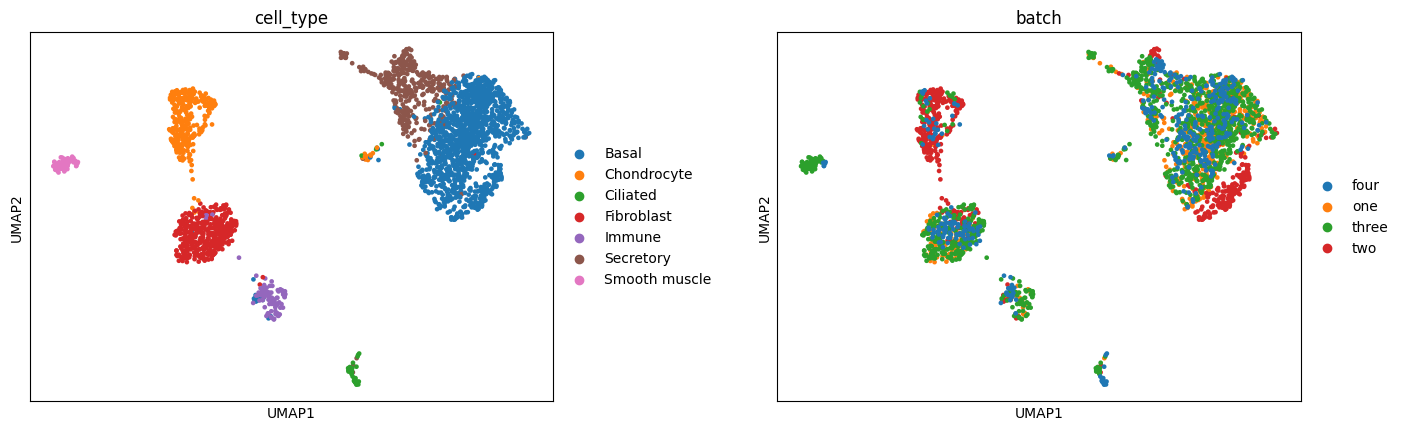

In [8]:
sc.pp.neighbors(adata, use_rep="X")
sc.tl.umap(adata)
sc.pl.umap(
    adata,
    color=["cell_type", "batch"],
    wspace=0.3,
)

## 3. Integrate cells with GLANCE

Fit GLANCE using the `batch` annotation. The integrated representation is stored in `adata.obsm["GLANCE"]`.

In [9]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

model = GLANCE(adata=adata, label_col="batch", random_state=SEED, device=device)

model.prepare_local_manifold()
model.prepare_geom_refinement()
model.fit_transform()

[GLANCE] Local manifold graph built | cells=2650, batches=4, k_pos=10, n_neg=20, far_quantile=0.70 | pos_edges=26500, neg_edges=53000
[GLANCE] Geometric refinement registered | start_epoch=2000, k_pos=10, n_neg=20, far_quantile=0.95, mutual=True, rebuild_every=None


[GLANCE] Ensemble: 1/3: 100%|█████| 2500/2500 [01:09<00:00, 36.16it/s]


[GLANCE] Training complete | Geometric edges: pos_edges=14786, neg_edges=53000
[GLANCE] Same-batch pos-edge fraction: 0.623 (random baseline: 0.250)


[GLANCE] Ensemble: 2/3: 100%|█████| 2500/2500 [01:09<00:00, 35.94it/s]


[GLANCE] Training complete | Geometric edges: pos_edges=15284, neg_edges=53000
[GLANCE] Same-batch pos-edge fraction: 0.629 (random baseline: 0.250)


[GLANCE] Ensemble: 3/3: 100%|█████| 2500/2500 [01:09<00:00, 35.77it/s]

[GLANCE] Training complete | Geometric edges: pos_edges=15030, neg_edges=53000
[GLANCE] Same-batch pos-edge fraction: 0.620 (random baseline: 0.250)


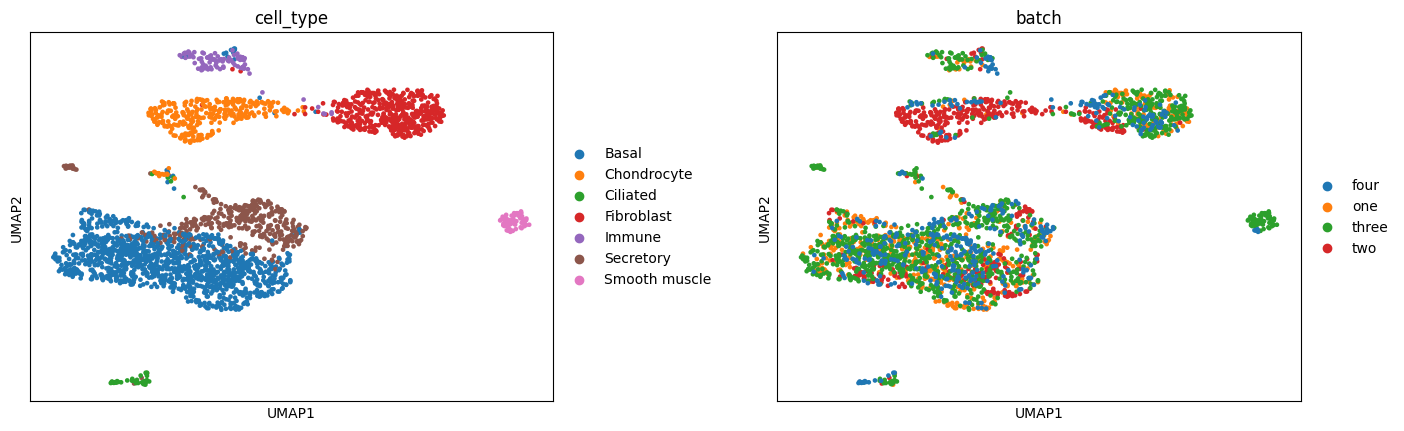

In [10]:
sc.pp.neighbors(adata, use_rep="GLANCE")
sc.tl.umap(adata)
sc.pl.umap(
    adata,
    color=["cell_type", "batch"],
    wspace=0.3,
)

## 4. Infer protein-level abundance scores

Select a reference batch and compute **abundance scores (AS)**. The scores are stored in `layers` for protein-level analyses and in `obsm` for representation-based operations such as Scanpy neighbors and UMAP.

In [11]:
ref_batch_info = model.select_reference_batch(cell_type_col="cell_type")
abundance_scores, tau, per_run = model.compute_abundance_scores(
    ref_batch=ref_batch_info[0],
    tau_method="bimodal",
)

adata.layers["abundance_scores"] = abundance_scores
adata.obsm["abundance_scores"] = abundance_scores

[GLANCE] select_reference_batch | cell_type_col=cell_type | summary: {1: 'label=one, n_cells=578, n_cell_types=6', 3: 'label=two, n_cells=515, n_cell_types=5', 2: 'label=three, n_cells=1111, n_cell_types=7', 0: 'label=four, n_cells=446, n_cell_types=7'} | selected: 2 (three)


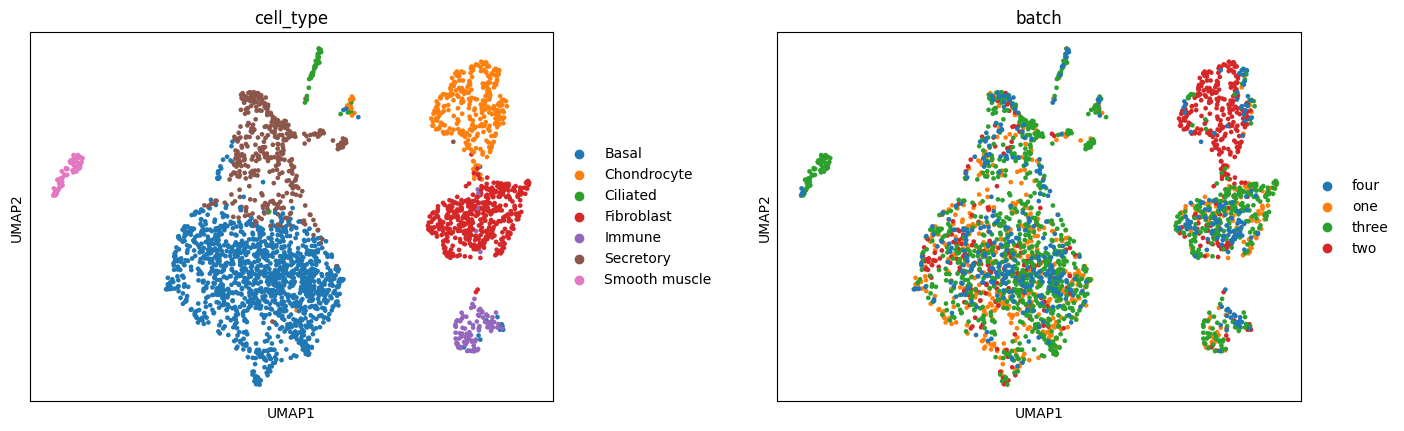

In [12]:
sc.pp.neighbors(adata, use_rep="abundance_scores")
sc.tl.umap(adata)
sc.pl.umap(
    adata,
    color=["cell_type", "batch"],
    wspace=0.3,
)

## 5. Compare cell–cell correlations

Compute Pearson correlations between cells, ordered by cell type. Both plots use identical color limits (−1 to 1), allowing a consistent visual comparison of scaled abundance and abundance scores.

In [13]:
def plot_cell_correlation(matrix, cell_types):
    labels = cell_types.astype(str).to_numpy()
    order = np.argsort(labels)
    labels = labels[order]

    X = matrix.toarray() if issparse(matrix) else np.asarray(matrix)
    corr = np.corrcoef(X[order])

    groups, counts = np.unique(labels, return_counts=True)
    boundaries = np.cumsum(counts)
    centers = boundaries - counts / 2 - 0.5

    _, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(
        corr,
        cmap="viridis",
        vmin=-1,
        vmax=1,
        interpolation="nearest",
    )
    ax.set_xticks(centers)
    ax.set_yticks(centers)
    ax.set_xticklabels(groups, rotation=90, fontsize=10)
    ax.set_yticklabels(groups, fontsize=10)

    for boundary in boundaries[:-1] - 0.5:
        ax.axhline(boundary, color="black", linewidth=0.5)
        ax.axvline(boundary, color="black", linewidth=0.5)

    plt.colorbar(im, ax=ax, label="Pearson correlation")
    plt.tight_layout()
    plt.show()

### Scaled abundance

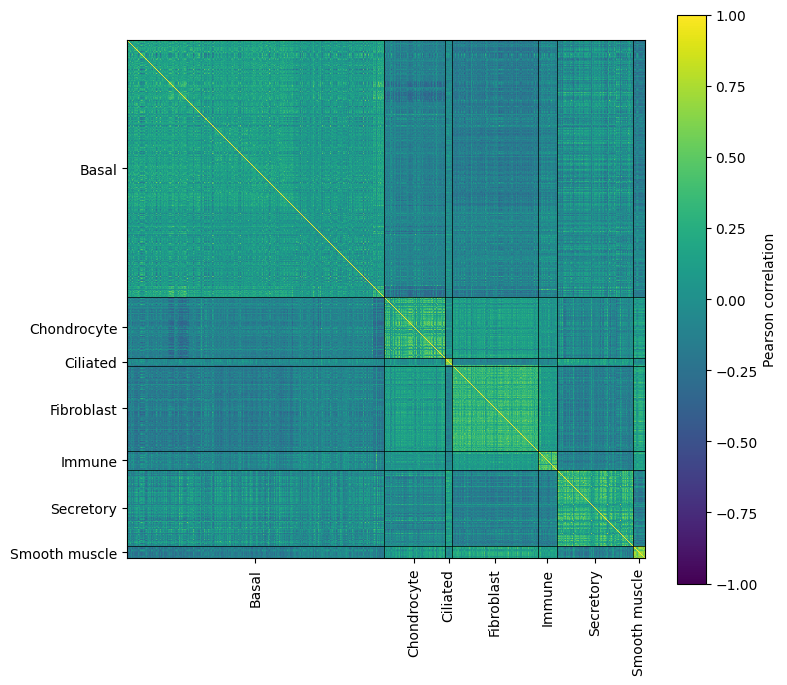

In [14]:
plot_cell_correlation(adata.X, adata.obs["cell_type"])

### Abundance scores

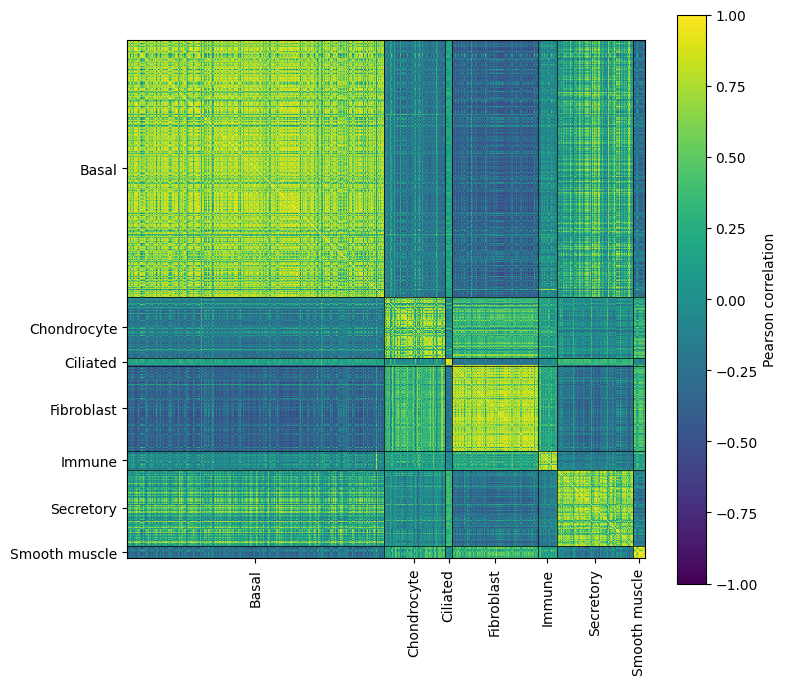

In [15]:
plot_cell_correlation(
    adata.layers["abundance_scores"],
    adata.obs["cell_type"],
)